In [ ]:
from pathlib import Path
BASE = Path("/home/lka/HYBRID_SARIMA")
print(BASE.exists(), BASE)

#Import the file to read it
import pandas as pd
disocupati_trimestral = pd.read_csv(BASE / 'data.csv', 
                       index_col='Period', 
                       parse_dates=True)
print(disocupati_trimestral)

True /home/lka/HYBRID_SARIMA
             15-34 M    15-34 F   35-49 M   35-49 F   50-74 M   50-74 F  \
Period                                                                    
2004-Q1    11.720628  17.198032  4.283283  8.776062  4.004764  5.376203   
2004-Q2    11.410664  16.187372  3.654493  7.196378  3.636536  4.515018   
2004-Q3    10.041510  15.682014  3.520125  6.945425  3.394804  3.976243   
2004-Q4    11.918557  17.227696  4.020448  7.582207  3.604743  3.583677   
2005-Q1    12.334781  16.852636  4.316241  7.577546  3.440298  4.204936   
...              ...        ...       ...       ...       ...       ...   
2025-Q2    11.341464  13.635416  5.106017  7.025122  3.776334  3.889283   
2025-Q3     9.628072  11.355385  4.656108  6.239399  3.108541  3.482718   
2025-Q4    10.903735  10.928362  3.989899  5.704370  3.250742  3.129547   
2026-Q1     9.534584  10.900056  4.316380  5.611548  2.984988  3.392216   
2026-Q2    10.244865  11.855438  5.044973  6.388627  3.268385  3.460483

/tmp/ipykernel_41292/1493313435.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  disocupati_trimestral = pd.read_csv(BASE / 'data.csv',


In [3]:
#Dividir el dataset en training, validation y test
series = [
    '15-34 M', '15-34 F',
    '35-49 M', '35-49 F',
    '50-74 M', '50-74 F',
    'Global_Rate'
]

# Ordenar cronológicamente
df = disocupati_trimestral.sort_index()

# División 70% Train, 15% Validation, 15% Test
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = df[series].iloc[:train_end].copy()
val = df[series].iloc[train_end:val_end].copy()
test = df[series].iloc[val_end:].copy()

# Mostrar resultados para cada serie
#for serie in series:
#    print(f"\nSerie: {serie}")
#    print(f"Train: {len(train[serie])} observaciones")
#    print(f"Validation: {len(val[serie])} observaciones")
#    print(f"Test: {len(test[serie])} observaciones")

print(train)
print(val)
print(test)


             15-34 M    15-34 F   35-49 M    35-49 F   50-74 M   50-74 F  \
Period                                                                     
2004-Q1    11.720628  17.198032  4.283283   8.776062  4.004764  5.376203   
2004-Q2    11.410664  16.187372  3.654493   7.196378  3.636536  4.515018   
2004-Q3    10.041510  15.682014  3.520125   6.945425  3.394804  3.976243   
2004-Q4    11.918557  17.227696  4.020448   7.582207  3.604743  3.583677   
2005-Q1    12.334781  16.852636  4.316241   7.577546  3.440298  4.204936   
...              ...        ...       ...        ...       ...       ...   
2018-Q2    17.908050  21.321705  7.759217  10.435680  6.683032  6.283515   
2018-Q3    16.802144  19.343542  6.191831   9.120602  5.538136  5.299045   
2018-Q4    19.322895  22.132355  7.396393  10.673055  6.327076  6.189145   
2019-Q1    19.163606  21.713279  8.111591  11.250865  6.697788  6.034775   
2019-Q2    17.128382  19.347371  7.161324   9.818228  5.738406  5.356958   

           

In [4]:

sarima_best_params={
    "15-34 M":{"order":(0,1,0),"seasonal_order":(0,1,1,4)},
    "15-34 F":{"order":(0,1,0),"seasonal_order":(0,1,1,4)},
    "35-49 M":{"order":(0,1,0),"seasonal_order":(1,1,2,4)},
    "35-49 F":{"order":(0,1,0),"seasonal_order":(0,1,1,4)},
    "50-74 M":{"order":(2,1,1),"seasonal_order":(0,1,1,4)},
    "50-74 F":{"order":(2,1,0),"seasonal_order":(0,1,1,4)},
    "Global_Rate":{"order":(0,1,0),"seasonal_order":(0,1,1,4)}
}


In [ ]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from itertools import product
from pathlib import Path
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)

architectures=[(32,),(64,),(128,),(32,32),(64,32),(64,64),(128,32),(128,64),(128,128)]
grid=list(product(architectures,[0.01,0.001],[4,6,8],[100,200],[16,32],[0.1,0.3,0.5]))

class LSTM(nn.Module):
    def __init__(self,neurons,dropout):
        super().__init__()
        self.layers=nn.ModuleList()
        size=1
        for n in neurons:
            self.layers.append(nn.LSTM(size,n,batch_first=True))
            size=n
        self.drop=nn.Dropout(dropout)
        self.fc=nn.Linear(size,1)

    def forward(self, x):                            # función forward de la LSTM
            for i, layer in enumerate(self.layers):
                x, _ = layer(x)
                if i == 0:
                    x = self.drop(x)                      # aplicar dropout solo a la primera capa LSTM
            return self.fc(x[:, -1, :])

def sequences(data,window,start,end):
    X=np.array([data[i-window:i] for i in range(start,end)],dtype=np.float32)
    y=np.array(data[start:end],dtype=np.float32)
    X=torch.tensor(X.reshape(-1,window,1),device=device)
    y=torch.tensor(y.reshape(-1,1),device=device)
    return X,y

def fit_lstm(res_train,res_val,params,final=False,best_epoch=None):
    neurons,lr,window,epochs,batch,dropout=params
    torch.manual_seed(42)
    scaler=MinMaxScaler()
    scaler.fit(res_train.reshape(-1,1))
    residuals=np.concatenate([res_train,res_val])
    z=scaler.transform(residuals.reshape(-1,1)).ravel()
    split=len(res_train)
    end=len(z) if final else split
    X,y=sequences(z,window,window,end)
    model=LSTM(neurons,dropout).to(device)
    optimizer=torch.optim.Adam(model.parameters(),lr=lr)
    criterion=nn.MSELoss()
    best=np.inf
    best_epoch_found=0
    wait=0
    total_epochs=best_epoch if final else epochs

    for epoch in range(total_epochs):
        model.train()
        idx=torch.randperm(len(X),device=device)

        for ids in idx.split(batch):
            optimizer.zero_grad()
            loss=criterion(model(X[ids]),y[ids])
            loss.backward()
            optimizer.step()

        if not final:
            model.eval()
            with torch.no_grad():
                Xv,yv=sequences(z,window,split,len(z))
                pred=model(Xv).cpu().numpy()
                actual=yv.cpu().numpy()

            pred=scaler.inverse_transform(pred)
            actual=scaler.inverse_transform(actual)
            mse=mean_squared_error(actual,pred)

            if mse<best-1e-10:
                best=mse
                best_epoch_found=epoch+1
                wait=0
            else:
                wait+=1

            if wait>=15:
                break

    if final:
        return model,scaler

    return best,best_epoch_found,epoch+1

grid_results=[]
results=[]
best_params={}
hybrid_predictions={}

for col,params in sarima_best_params.items():
    y_train=train[col]
    y_val=val[col]
    y_train_val=pd.concat([y_train,y_val])
    y_test=test[col]

    sarima_train=SARIMAX(
        y_train.reset_index(drop=True),
        order=params["order"],
        seasonal_order=params["seasonal_order"],
        enforce_stationarity=True,
        enforce_invertibility=True
    ).fit(disp=False)

    burn=sarima_train.loglikelihood_burn
    res_train=sarima_train.resid.to_numpy()[burn:]
    sarima_val=np.asarray(sarima_train.forecast(steps=len(y_val)))
    res_val=y_val.to_numpy()-sarima_val

    best_mse=np.inf
    best_config=None
    best_epoch=0

    for config in grid:
        mse,epoch,trained=fit_lstm(res_train,res_val,config)
        neurons,lr,window,epochs,batch,dropout=config

        grid_results.append([
            col,len(neurons),str(neurons),lr,window,
            epochs,epoch,trained,batch,dropout,mse
        ])

        if mse<best_mse:
            best_mse=mse
            best_config=config
            best_epoch=epoch

    best_params[col]={
        "params":best_config,
        "best_epoch":best_epoch,
        "MSE_Validation":best_mse
    }

    sarima=SARIMAX(
        y_train_val.reset_index(drop=True),
        order=params["order"],
        seasonal_order=params["seasonal_order"],
        enforce_stationarity=True,
        enforce_invertibility=True
    ).fit(disp=False)

    residuals=sarima.resid.to_numpy()[sarima.loglikelihood_burn:]

    lstm,scaler=fit_lstm(
        residuals,
        np.array([]),
        best_config,
        final=True,
        best_epoch=best_epoch
    )

    sarima_pred=np.asarray(sarima.forecast(steps=len(y_test)))
    history=list(residuals)
    lstm_pred=[]

    for i in range(len(y_test)):
        window=best_config[2]
        x=np.array(history[-window:]).reshape(-1,1)
        x=scaler.transform(x)
        x=torch.tensor(x.reshape(1,window,1),dtype=torch.float32,device=device)

        lstm.eval()
        with torch.no_grad():
            pred=lstm(x).cpu().numpy()

        pred=scaler.inverse_transform(pred)[0,0]
        lstm_pred.append(pred)
        history.append(float(y_test.iloc[i])-sarima_pred[i])

    lstm_pred=np.array(lstm_pred)
    hybrid_pred=sarima_pred+lstm_pred
    real=y_test.to_numpy()

    mae=mean_absolute_error(real,hybrid_pred)
    mse=mean_squared_error(real,hybrid_pred)
    rmse=np.sqrt(mse)
    mask=real!=0
    mape=np.mean(np.abs((real[mask]-hybrid_pred[mask])/real[mask]))*100 if mask.any() else np.nan

    values=y_train_val.to_numpy()
    scale=np.mean(np.abs(values[4:]-values[:-4]))
    mase=mae/scale if scale>0 else np.nan
    r2=r2_score(real,hybrid_pred)

    results.append([col,mae,mse,rmse,mape,mase,r2])

    hybrid_predictions[col]=pd.DataFrame({
        "Observed":real,
        "SARIMA":sarima_pred,
        "LSTM_Residual":lstm_pred,
        "Hybrid":hybrid_pred
    },index=y_test.index)

    print(col,"Validation MSE:",round(best_mse,4),"Test MSE:",round(mse,4))

grid_df=pd.DataFrame(grid_results,columns=[
    "Serie","Layers","Neurons","Learning_Rate","Window",
    "Epochs","Best_Epoch","Epochs_Trained","Batch_Size",
    "Dropout","MSE"
])

grid_df=grid_df.sort_values(["Serie","MSE"]).reset_index(drop=True)
grid_df["Rank"]=grid_df.groupby("Serie").cumcount()+1
top10=grid_df[grid_df["Rank"]<=10]

results_df=pd.DataFrame(results,columns=[
    "Serie","MAE","MSE","RMSE","MAPE","MASE","R2"
])

output=Path("results/SARIMA_LSTM_Sequential")
output.mkdir(parents=True,exist_ok=True)

top10.to_csv(output/"top10_sarima_lstm.csv",index=False)
results_df.to_csv(output/"sarima_lstm_test.csv",index=False)

for col,pred in hybrid_predictions.items():
    pred.to_csv(output/f"pred_{col.replace(' ','_')}.csv")

print(results_df.round(4))    
print(best_params)  

  

15-34 M Validation MSE: 3.1899 Test MSE: 1.5083
15-34 F Validation MSE: 3.3918 Test MSE: 1.2144
35-49 M Validation MSE: 0.2538 Test MSE: 0.6475
35-49 F Validation MSE: 1.0972 Test MSE: 1.5042


/home/lka/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/lka/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/lka/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/home/lka/.venv/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


50-74 M Validation MSE: 0.2585 Test MSE: 0.1954
50-74 F Validation MSE: 0.2653 Test MSE: 2.6965
Global_Rate Validation MSE: 0.698 Test MSE: 0.278
         Serie     MAE     MSE    RMSE     MAPE    MASE      R2
0      15-34 M  1.0801  1.5083  1.2281   9.6965  0.5759 -0.2343
1      15-34 F  0.8499  1.2144  1.1020   7.0044  0.4790  0.5001
2      35-49 M  0.6470  0.6475  0.8047  14.0080  0.9791 -0.8079
3      35-49 F  1.0068  1.5042  1.2264  15.5419  1.1508 -0.1933
4      50-74 M  0.3520  0.1954  0.4420  10.4651  0.5862  0.4612
5      50-74 F  1.3649  2.6965  1.6421  36.6672  2.4489 -2.0368
6  Global_Rate  0.4099  0.2780  0.5273   6.8641  0.4537  0.6675
{'15-34 M': {'params': ((32,), 0.01, 4, 100, 16, 0.5), 'best_epoch': 4, 'MSE_Validation': 3.1899261474609375}, '15-34 F': {'params': ((128, 32), 0.001, 4, 100, 32, 0.5), 'best_epoch': 15, 'MSE_Validation': 3.3918468952178955}, '35-49 M': {'params': ((128, 64), 0.01, 4, 100, 16, 0.3), 'best_epoch': 77, 'MSE_Validation': 0.25375130772590637},

In [ ]:
lstm_best_params={
    "15-34 M":{"neurons":(32,),"lr":0.01,"window":4,"epochs":100,"batch":16,"dropout":0.5},
    "15-34 F":{"neurons":(128,32),"lr":0.001,"window":4,"epochs":100,"batch":32,"dropout":0.5},
    "35-49 M":{"neurons":(128,64),"lr":0.01,"window":4,"epochs":100,"batch":16,"dropout":0.3},
    "35-49 F":{"neurons":(128,32),"lr":0.001,"window":4,"epochs":100,"batch":32,"dropout":0.5},
    "50-74 M":{"neurons":(128,128),"lr":0.01,"window":6,"epochs":100,"batch":16,"dropout":0.1},
    "50-74 F":{"neurons":(128,128),"lr":0.01,"window":8,"epochs":100,"batch":16,"dropout":0.5},
    "Global_Rate":{"neurons":(64,64),"lr":0.01,"window":6,"epochs":100,"batch":32,"dropout":0.5}
}

In [5]:
# Academic style
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", font_scale=1.3)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "savefig.bbox": "tight"
})

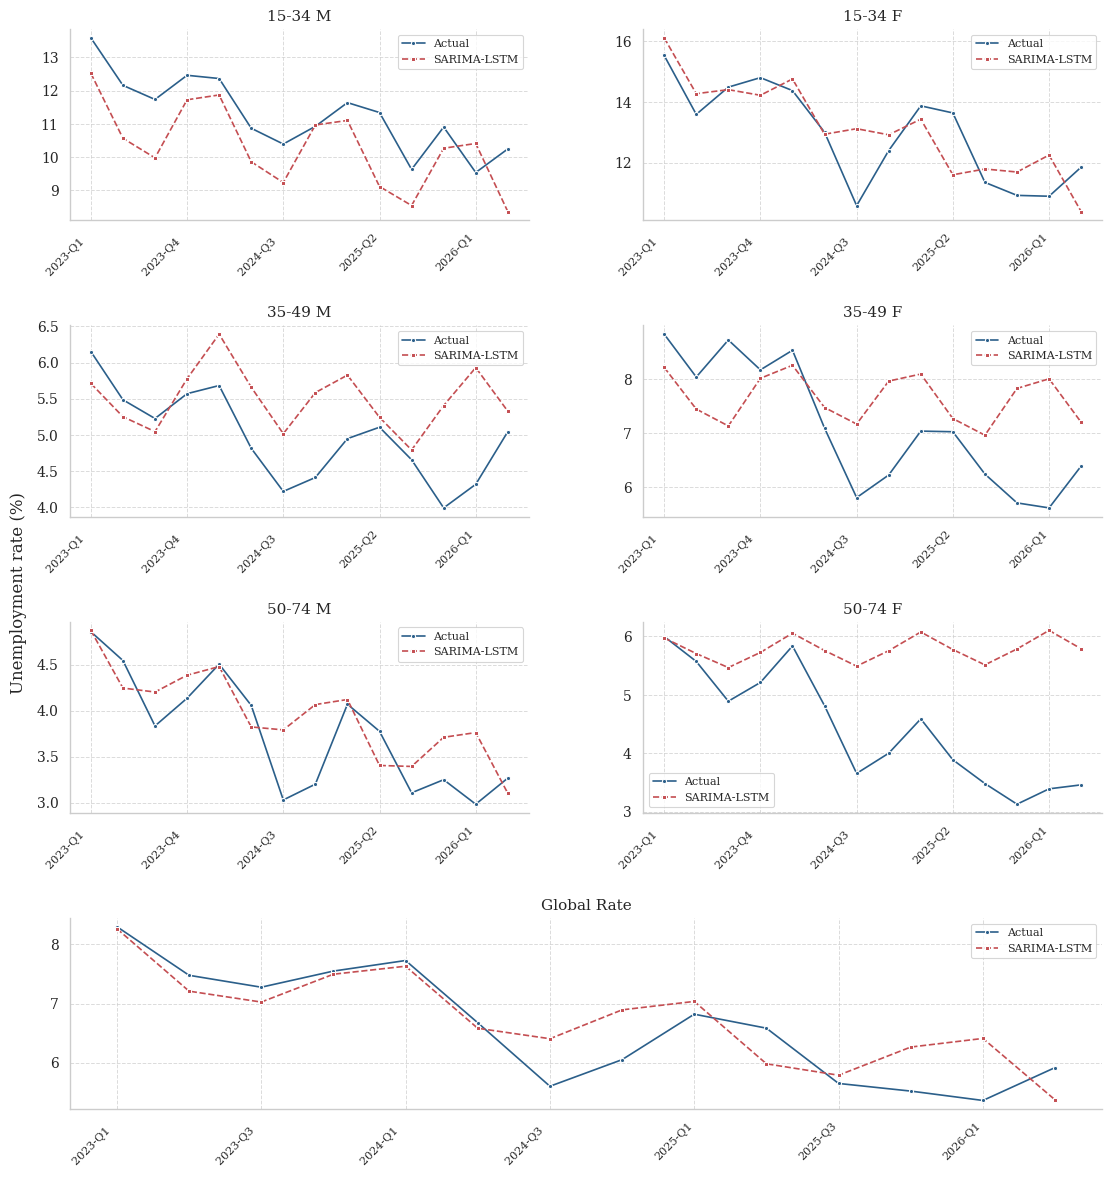

In [20]:
series = ["15-34 M","15-34 F","35-49 M","35-49 F",
          "50-74 M","50-74 F","Global_Rate"]

fig = plt.figure(figsize=(12,12))
gs = fig.add_gridspec(4,2,hspace=0.55,wspace=0.25)
axes = [fig.add_subplot(gs[i//2,i%2]) for i in range(6)]
axes.append(fig.add_subplot(gs[3,:]))

for i,(ax,col) in enumerate(zip(axes,series)):
    #leer de los archivos guardados en la carpeta SARIMA_LSTM_sequential
    #df = hybrid_predictions[col]
    df = pd.read_csv(BASE /"results"/"SARIMA_LSTM_Sequential" / f"pred_{col.replace(' ', '_')}.csv", index_col=0)
    x = df.index

    sns.lineplot(x=x,y=df["Observed"],ax=ax,color="#2B5F8A",
                 marker="o",markersize=3,linewidth=1.2,label="Actual")

    sns.lineplot(x=x,y=df["Hybrid"],ax=ax,color="#C44E52",
                 marker="s",markersize=3,linewidth=1.2,
                 linestyle="--",label="SARIMA-LSTM")

    ax.set_title(col.replace("_"," "),fontsize=11)
    ax.set(xlabel="",ylabel="")
    ticks = x[::2] if i==6 else x[::3]
    ax.set_xticks(ticks)
    ax.set_xticklabels(ticks,rotation=45,ha="right",fontsize=8)
    ax.grid(True,linestyle="--",linewidth=0.7,alpha=0.7)
    ax.legend(fontsize=8)
    sns.despine(ax=ax)

fig.supylabel("Unemployment rate (%)",fontsize=12,x=0.07)
fig.subplots_adjust(left=0.12,right=0.98,top=0.97,bottom=0.07)

IMG = BASE / "IMG"
IMG.mkdir(parents=True,exist_ok=True)
fig.savefig(IMG/"sarima_lstm_sequential_forecast_test.pdf",bbox_inches="tight")
plt.show()

In [23]:
rng = np.random.default_rng(42)
B, block_size = 2000, 4
ci_results = []

for col in sarima_best_params:
    df = pd.read_csv(BASE/"results"/"SARIMA_LSTM_Sequential"/f"pred_{col.replace(' ','_')}.csv")

    real = df["Observed"].to_numpy()
    pred = df["Hybrid"].to_numpy()
    n = len(real)

    if n < block_size:
        raise ValueError(f"{col}: test demasiado corto")

    def calc(y, p):
        e = y-p
        mask = y != 0
        return {
            "MSE": np.mean(e**2),
            "RMSE": np.sqrt(np.mean(e**2)),
            "MAE": np.mean(np.abs(e)),
            "MAPE": np.mean(np.abs(e[mask]/y[mask]))*100 if mask.any() else np.nan
        }

    point = calc(real, pred)
    boot = {m: [] for m in point}

    for _ in range(B):
        starts = rng.integers(0,n-block_size+1,size=int(np.ceil(n/block_size)))
        idx = np.concatenate([np.arange(s,s+block_size) for s in starts])[:n]

        for m,v in calc(real[idx],pred[idx]).items():
            boot[m].append(v)

    row = {"Serie": col}
    for m in point:
        lo,hi = np.nanpercentile(boot[m],[2.5,97.5])
        row[m] = round(point[m],4)
        row[f"{m} IC 95%"] = f"[{lo:.4f}, {hi:.4f}]"

    ci_results.append(row)

sarima_lstm_ci_df = pd.DataFrame(ci_results)
sarima_lstm_ci_df.to_csv(BASE/"results"/"SARIMA_LSTM_Sequential"/"sarima_lstm_IC_test.csv",index=False)
display(sarima_lstm_ci_df)

,Serie,MSE,MSE IC 95%,RMSE,RMSE IC 95%,MAE,MAE IC 95%,MAPE,MAPE IC 95%
0,15-34 M,1.5083,"[0.8595, 1.8615]",1.2281,"[0.9271, 1.3644]",1.0801,"[0.7877, 1.2217]",9.6965,"[7.0634, 10.9690]"
1,15-34 F,1.2144,"[0.4926, 2.0702]",1.1020,"[0.7018, 1.4388]",0.8499,"[0.5057, 1.1199]",7.0044,"[3.9398, 9.4666]"
2,35-49 M,0.6475,"[0.2570, 0.9615]",0.8047,"[0.5070, 0.9805]",0.6470,"[0.4022, 0.8413]",14.0080,"[7.8875, 19.0489]"
3,35-49 F,1.5042,"[0.7278, 2.2099]",1.2264,"[0.8531, 1.4866]",1.0068,"[0.6582, 1.2731]",15.5419,"[8.6803, 21.0846]"
4,50-74 M,0.1954,"[0.0878, 0.3230]",0.4420,"[0.2964, 0.5684]",0.3520,"[0.2540, 0.4740]",10.4651,"[6.7042, 14.6348]"
5,50-74 F,2.6965,"[0.6131, 4.4435]",1.6421,"[0.7830, 2.1080]",1.3649,"[0.5982, 2.0453]",36.6672,"[12.9662, 57.1406]"
6,Global_Rate,0.2780,"[0.0776, 0.4266]",0.5273,"[0.2787, 0.6532]",0.4099,"[0.2018, 0.5618]",6.8641,"[2.9888, 9.6628]"
